In [39]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/processed/car_details_processed.csv')

In [40]:
X = df.drop('selling_price', axis=1)
y = np.log1p(df['selling_price'])

In [41]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 4781
Validation: 1024
Test: 1025


In [42]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [43]:
from sklearn.neighbors import KNeighborsRegressor

In [44]:

from sklearn.metrics import mean_squared_error
k_values = [3, 5, 7, 9, 11, 15, 20, 25, 30]
results = []
for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_val_pred = knn.predict(X_val_scaled)

    rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

    results.append({
        'K': k,
        'Validation RMSE': rmse
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='Validation RMSE')

results_df

,K,Validation RMSE
1,5,0.298561
0,3,0.299121
2,7,0.309668
3,9,0.315005
4,11,0.323751
5,15,0.340178
6,20,0.343761
7,25,0.346834
8,30,0.353419


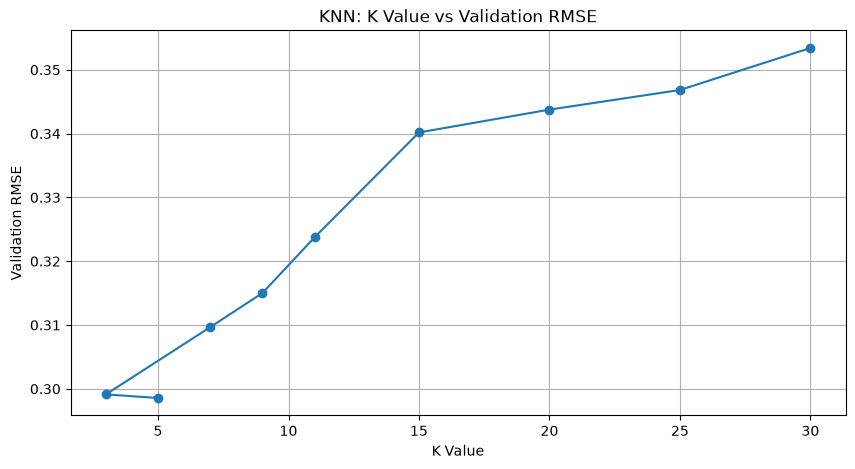

In [45]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(
    results_df['K'],
    results_df['Validation RMSE'],
    marker='o'
)
plt.xlabel('K Value')
plt.ylabel('Validation RMSE')
plt.title('KNN: K Value vs Validation RMSE')
plt.grid(True)
plt.show()

In [46]:
best_k = int(results_df.iloc[0]['K'])
print("Best K:", best_k)
print("Best Validation RMSE:", results_df.iloc[0]['Validation RMSE'])

Best K: 5
Best Validation RMSE: 0.29856061800183686


In [47]:
X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])
print("Final Training Size:", len(X_train_full))

Final Training Size: 5805


In [48]:
scaler_final = StandardScaler()

X_train_full_scaled = scaler_final.fit_transform(X_train_full)
X_test_final_scaled = scaler_final.transform(X_test)

In [49]:
best_k = int(results_df.iloc[0]['K'])

knn_final = KNeighborsRegressor(n_neighbors=best_k)

knn_final.fit(X_train_full_scaled, y_train_full)

print("Final KNN Model Trained Successfully!")
print("Best K:", best_k)

Final KNN Model Trained Successfully!
Best K: 5


In [50]:
import os
import joblib
os.makedirs("models", exist_ok=True)
knn_package = {
    "model": knn_final,
    "scaler": scaler_final,
    "target_transform": "log1p"
}
joblib.dump(knn_package, "models/knn_model.pkl")
print("KNN Model Saved Successfully!")

KNN Model Saved Successfully!


In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_test_pred = knn_final.predict(X_test_final_scaled)

y_test_original = np.expm1(y_test)
y_test_pred_original = np.expm1(y_test_pred)

mae = mean_absolute_error(y_test_original, y_test_pred_original)
mse = mean_squared_error(y_test_original, y_test_pred_original)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_original, y_test_pred_original)

print("KNN Final Test Results")
print("----------------------")
print("Best K:", best_k)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

KNN Final Test Results
----------------------
Best K: 5
MAE: 109807.03834758542
MSE: 69682459129.21484
RMSE: 263974.353165634
R2 Score: 0.7782105684177631


In [52]:
comparison = pd.DataFrame({
    'Actual Price': y_test_original.values,
    'Predicted Price': y_test_pred_original
})
comparison.head(10)

,Actual Price,Predicted Price
0,409999.0,2.281326e+05
1,550000.0,5.995142e+05
2,750000.0,6.981850e+05
3,120000.0,1.614069e+05
4,1445000.0,1.202664e+06
5,450000.0,4.465464e+05
6,700000.0,6.074255e+05
7,375000.0,3.539663e+05
8,550000.0,4.057989e+05
9,250000.0,2.431186e+05


In [53]:
knn_results = pd.DataFrame({
    'Model': ['KNN Regressor'],
    'MAE': [mae],
    'RMSE': [rmse],
    'R2 Score': [r2]
})
display(knn_results)

,Model,MAE,RMSE,R2 Score
0,KNN Regressor,109807.038348,263974.353166,0.778211


In [54]:
import os
os.makedirs("../results", exist_ok=True)
knn_results.to_csv("../results/knn_results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!
